# Week 5: Risk Analysis Improvement and Decision Support

## Objective of the Study

The main objective of this analysis is to measure agricultural risk using variability in yield rather than relying only on average yield.

In traditional agricultural analysis, average yield is often used as the primary indicator of performance. However, average yield alone can be misleading because it does not capture fluctuations in production across different years.

To address this limitation, this study uses the Coefficient of Variation (CV) as a measure of risk. CV represents the relative variability in yield and helps in understanding how stable or unstable agricultural production is over time.

A higher CV indicates higher variability and therefore higher risk, while a lower CV indicates more stable and reliable yield. By focusing on CV, this analysis provides a more realistic understanding of agricultural risk, which is important for farmers, policymakers, and decision-making systems.

This approach helps in developing better decision-support systems by identifying not only high-yield crops but also low-risk and stable agricultural options.

## Risk Validation Using Different Thresholds

To ensure that the risk classification is reliable, the stability of risk categories is tested by changing the threshold values of the Coefficient of Variation (CV).

Initially, risk categories were defined using fixed thresholds. However, these thresholds may affect how data points are classified. Therefore, multiple threshold combinations are tested to check whether the classification remains stable.

If the risk categories remain similar even after changing thresholds, it indicates that the model is robust. If the categories change significantly, it suggests that the classification method is sensitive and less reliable.

In [1]:
import pandas as pd

# Load dataset
data = pd.read_csv("agri_combined_datasets.csv")

# Clean column names (important)
data.columns = data.columns.str.strip().str.lower()

# Check data
data.head()

,state,district,crop,year,area,production,yield,annual_rainfall,n_high,n_medium,...,k_medium,k_low,oc_high,oc_medium,oc_low,ph_alkaline,ph_acidic,ph_neutral,ec_nonsaline,ec_saline
0,andhra pradesh,alluri sitharama raju,Cotton(lint),2022,2682.0,7614.0,2.84,1080.7,3.26,54.11,...,44.99,29.87,27.25,64.48,8.27,0.12,18.93,80.95,99.81,0.19
1,andhra pradesh,anakapalli,Cotton(lint),2022,82.0,230.0,2.80,1080.7,12.10,25.02,...,22.88,8.79,12.98,25.62,61.40,0.62,0.10,99.27,98.99,1.01
2,andhra pradesh,anantapur,Cotton(lint),2012,28000.0,35000.0,1.25,536.0,0.06,11.63,...,27.33,1.74,4.00,11.80,84.21,0.88,0.02,99.10,99.61,0.39
3,andhra pradesh,anantapur,Cotton(lint),2013,37661.0,77316.0,2.05,501.7,0.06,11.63,...,27.33,1.74,4.00,11.80,84.21,0.88,0.02,99.10,99.61,0.39
4,andhra pradesh,anantapur,Cotton(lint),2014,73734.0,103779.0,1.41,437.8,0.06,11.63,...,27.33,1.74,4.00,11.80,84.21,0.88,0.02,99.10,99.61,0.39


In [2]:
print(data.columns)

Index(['state', 'district', 'crop', 'year', 'area', 'production', 'yield',
       'annual_rainfall', 'n_high', 'n_medium', 'n_low', 'p_high', 'p_medium',
       'p_low', 'k_high', 'k_medium', 'k_low', 'oc_high', 'oc_medium',
       'oc_low', 'ph_alkaline', 'ph_acidic', 'ph_neutral', 'ec_nonsaline',
       'ec_saline'],
      dtype='str')


In [3]:
# Group by state and crop (or whatever you used before)
grouped = data.groupby(['state', 'crop'])['yield']

# Calculate mean and std
stats = grouped.agg(['mean', 'std']).reset_index()

# Calculate CV
stats['cv'] = (stats['std'] / stats['mean']) * 100

# Merge back to main data
data = pd.merge(data, stats[['state', 'crop', 'cv']], on=['state', 'crop'], how='left')

data.head()

,state,district,crop,year,area,production,yield,annual_rainfall,n_high,n_medium,...,k_low,oc_high,oc_medium,oc_low,ph_alkaline,ph_acidic,ph_neutral,ec_nonsaline,ec_saline,cv
0,andhra pradesh,alluri sitharama raju,Cotton(lint),2022,2682.0,7614.0,2.84,1080.7,3.26,54.11,...,29.87,27.25,64.48,8.27,0.12,18.93,80.95,99.81,0.19,46.322326
1,andhra pradesh,anakapalli,Cotton(lint),2022,82.0,230.0,2.80,1080.7,12.10,25.02,...,8.79,12.98,25.62,61.40,0.62,0.10,99.27,98.99,1.01,46.322326
2,andhra pradesh,anantapur,Cotton(lint),2012,28000.0,35000.0,1.25,536.0,0.06,11.63,...,1.74,4.00,11.80,84.21,0.88,0.02,99.10,99.61,0.39,46.322326
3,andhra pradesh,anantapur,Cotton(lint),2013,37661.0,77316.0,2.05,501.7,0.06,11.63,...,1.74,4.00,11.80,84.21,0.88,0.02,99.10,99.61,0.39,46.322326
4,andhra pradesh,anantapur,Cotton(lint),2014,73734.0,103779.0,1.41,437.8,0.06,11.63,...,1.74,4.00,11.80,84.21,0.88,0.02,99.10,99.61,0.39,46.322326


In [4]:
# Function to classify risk based on thresholds
def classify_risk(cv, low_thresh, high_thresh):
    if cv < low_thresh:
        return "Low"
    elif cv < high_thresh:
        return "Medium"
    else:
        return "High"

# Create different threshold settings
thresholds = [
    (20, 40),   # Original
    (15, 35),   # Strict
    (25, 50)    # Relaxed
]

# Apply classifications
for low, high in thresholds:
    col_name = f"risk_{low}_{high}"
    data[col_name] = data["cv"].apply(lambda x: classify_risk(x, low, high))

# Check distribution
for low, high in thresholds:
    col_name = f"risk_{low}_{high}"
    print(f"\nThresholds: {low}-{high}")
    print(data[col_name].value_counts())


Thresholds: 20-40
risk_20_40
Medium    3654
High      3163
Name: count, dtype: int64

Thresholds: 15-35
risk_15_35
High      4582
Medium    2235
Name: count, dtype: int64

Thresholds: 25-50
risk_25_50
Medium    4211
High      2135
Low        471
Name: count, dtype: int64


### Interpretation of Risk Validation

The comparison of risk categories under different threshold values shows noticeable changes in classification.

When stricter thresholds (15–35) are used, a larger number of observations fall into the high-risk category. On the other hand, when more relaxed thresholds (25–50) are applied, some observations shift into the low-risk category and the number of high-risk observations decreases.

This indicates that the risk classification based on CV is sensitive to the choice of threshold values. Therefore, the selection of thresholds plays an important role in determining risk levels.

Despite this sensitivity, the overall pattern still shows a significant presence of medium and high-risk categories, suggesting that variability in agricultural yield is an important factor in risk assessment.

This validation step highlights the need for careful threshold selection when designing decision-support systems, as different threshold choices can influence risk interpretation and policy decisions.

## Linking Risk with Agricultural Factors

To make the risk analysis more meaningful, the Coefficient of Variation (CV) is linked with important agricultural factors such as rainfall, crop type, and state.

These factors influence agricultural productivity in different ways. Rainfall affects crop growth, crop type determines sensitivity to environmental conditions, and state represents regional differences such as soil and irrigation.

However, rainfall alone cannot fully explain agricultural risk. Instead, risk is influenced by a combination of multiple factors. Therefore, this analysis explores how CV (risk) varies across these factors to provide better insights for decision-making.

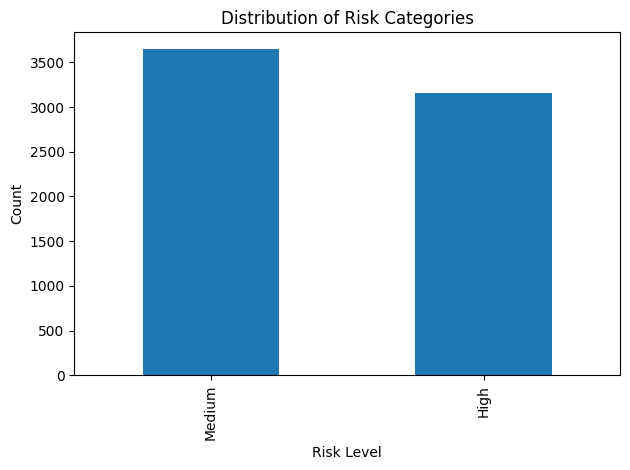

In [5]:
import matplotlib.pyplot as plt

# Use one risk column (original thresholds)
data['risk'] = data['risk_20_40']

# Count values
risk_counts = data['risk'].value_counts()

plt.figure()
risk_counts.plot(kind='bar')
plt.title("Distribution of Risk Categories")
plt.xlabel("Risk Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Figure 1: Distribution of risk categories based on CV.

The graph shows that most observations fall under medium and high-risk categories, indicating that agricultural production is not consistently stable.

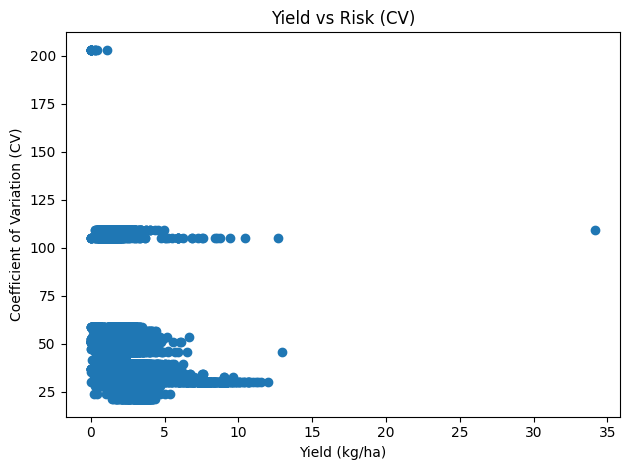

In [6]:
plt.figure()
plt.scatter(data['yield'], data['cv'])
plt.title("Yield vs Risk (CV)")
plt.xlabel("Yield (kg/ha)")
plt.ylabel("Coefficient of Variation (CV)")
plt.tight_layout()
plt.show()

Figure 2: Relationship between yield and risk.

The scatter plot shows that high yield does not always correspond to low risk. Some observations with high yield also show high variability, confirming that productivity and stability are different.

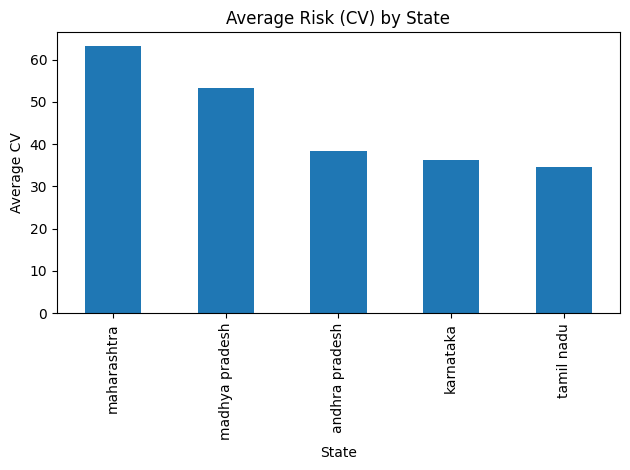

In [7]:
state_risk = data.groupby('state')['cv'].mean().sort_values(ascending=False)

plt.figure()
state_risk.plot(kind='bar')
plt.title("Average Risk (CV) by State")
plt.xlabel("State")
plt.ylabel("Average CV")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [8]:
print(data[['annual_rainfall', 'cv']].dtypes)

annual_rainfall    float64
cv                 float64
dtype: object


In [9]:

data['annual_rainfall'] = pd.to_numeric(data['annual_rainfall'], errors='coerce')
data['cv'] = pd.to_numeric(data['cv'], errors='coerce')

In [10]:

data = data.dropna(subset=['annual_rainfall', 'cv'])

Figure 3: State-wise average risk.

The graph shows clear differences in risk levels across states. Some states have higher average CV, indicating unstable agricultural conditions, while others show more stable yield patterns.

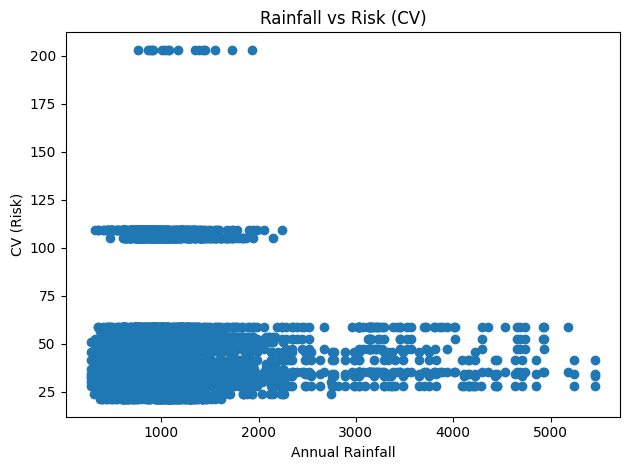

In [11]:
plt.figure()
plt.scatter(data['annual_rainfall'], data['cv'])
plt.title("Rainfall vs Risk (CV)")
plt.xlabel("Annual Rainfall")
plt.ylabel("CV (Risk)")
plt.tight_layout()
plt.show()

In [12]:
print(data.columns)

Index(['state', 'district', 'crop', 'year', 'area', 'production', 'yield',
       'annual_rainfall', 'n_high', 'n_medium', 'n_low', 'p_high', 'p_medium',
       'p_low', 'k_high', 'k_medium', 'k_low', 'oc_high', 'oc_medium',
       'oc_low', 'ph_alkaline', 'ph_acidic', 'ph_neutral', 'ec_nonsaline',
       'ec_saline', 'cv', 'risk_20_40', 'risk_15_35', 'risk_25_50', 'risk'],
      dtype='str')


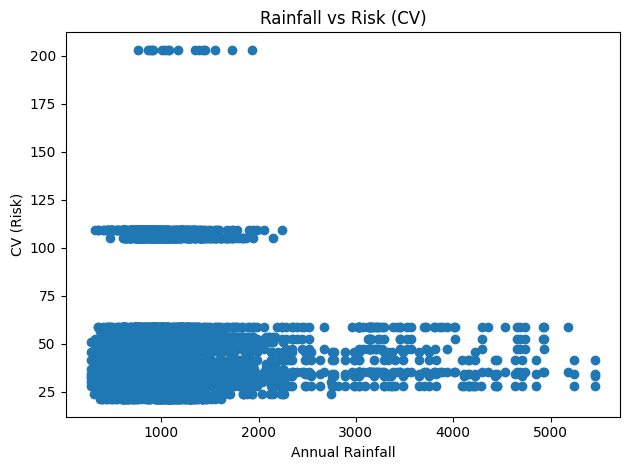

In [13]:
plt.figure()
plt.scatter(data['annual_rainfall'], data['cv'])
plt.title("Rainfall vs Risk (CV)")
plt.xlabel("Annual Rainfall")
plt.ylabel("CV (Risk)")
plt.tight_layout()
plt.show()

In [14]:
print(data[['annual_rainfall', 'cv']].dtypes)

annual_rainfall    float64
cv                 float64
dtype: object


In [15]:
data['annual_rainfall'] = pd.to_numeric(data['annual_rainfall'], errors='coerce')
data['cv'] = pd.to_numeric(data['cv'], errors='coerce')

In [16]:
data = data.dropna(subset=['annual_rainfall', 'cv'])

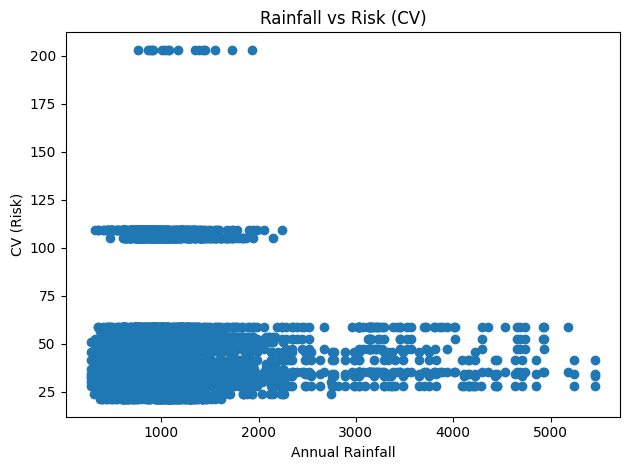

In [17]:
plt.figure()
plt.scatter(data['annual_rainfall'], data['cv'])
plt.title("Rainfall vs Risk (CV)")
plt.xlabel("Annual Rainfall")
plt.ylabel("CV (Risk)")
plt.tight_layout()
plt.show()

Figure 4: Relationship between rainfall and risk.

The scatter plot shows that rainfall alone does not strongly explain agricultural risk. While rainfall influences crop growth and yield, the variability in yield is affected by multiple factors such as crop type, regional conditions, and farming practices.

This indicates that rainfall is an important but not sufficient factor for determining agricultural risk.

In [18]:
data = data.dropna()

## Explainable AI Model for Risk Prediction

To further strengthen the analysis, a machine learning model is used to predict agricultural risk categories based on multiple factors such as yield, rainfall, crop type, and state.

A Random Forest classifier is used for this purpose because it is robust and provides feature importance, which helps in understanding which factors contribute most to agricultural risk.

This approach adds an Explainable AI (XAI) component to the study by not only predicting risk but also explaining the key drivers behind it.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

In [20]:
from sklearn.model_selection import train_test_split

## Crop-wise Risk Comparison

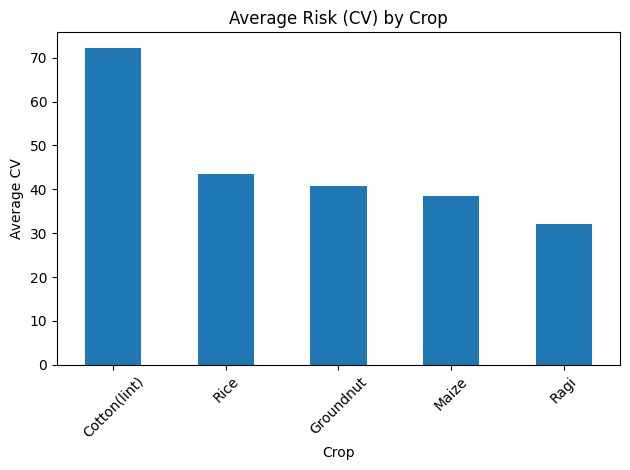

In [21]:
crop_risk = data.groupby('crop')['cv'].mean().sort_values(ascending=False)

plt.figure()
crop_risk.plot(kind='bar')
plt.title("Average Risk (CV) by Crop")
plt.xlabel("Crop")
plt.ylabel("Average CV")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Figure 5: Crop-wise average risk.

The graph shows that certain crops carry consistently higher risk (CV) 
regardless of the state they are grown in, while others remain stable 
across regions. This confirms that crop type is an important factor 
in agricultural risk, alongside rainfall and state.

In [22]:
from sklearn.preprocessing import LabelEncoder

le_state = LabelEncoder()
le_crop = LabelEncoder()
data['state_enc'] = le_state.fit_transform(data['state'])
data['crop_enc'] = le_crop.fit_transform(data['crop'])

## Explainable AI Model for Risk Prediction

To further strengthen the analysis, a Random Forest classifier is trained 
to predict the risk category (Low / Medium / High) using yield, CV, 
rainfall, state, and crop as inputs. Random Forest is chosen because it 
is robust to non-linear relationships and provides feature importance, 
allowing us to explain which factors drive agricultural risk the most.

In [23]:
from sklearn.model_selection import GroupShuffleSplit

# Create a group identifier — one per unique state-crop combination
data['group_id'] = data['state'] + "_" + data['crop']

X = data[['yield', 'annual_rainfall', 'state_enc', 'crop_enc']]
y = data['risk']
groups = data['group_id']

# Split by GROUP, not by row — no state-crop pair appears in both sets
gss = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (5340, 4)
Test size: (1462, 4)


In [24]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_leaf=5,
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Train accuracy:", rf_model.score(X_train, y_train))
print("Test accuracy:", rf_model.score(X_test, y_test))

Train accuracy: 0.998689138576779
Test accuracy: 0.6963064295485636


In [25]:
importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance)

           feature  importance
3         crop_enc    0.520537
2        state_enc    0.288378
0            yield    0.176652
1  annual_rainfall    0.014433


### Interpretation of Feature Importance

Note: under the original thresholds (CV < 20 = Low, 20–40 = Medium, 
>40 = High), no observations in this dataset fall into the "Low" risk 
category — the data only splits into Medium (54.5%) and High (45.5%) 
risk. This is itself a meaningful finding: under this classification 
scheme, no part of the dataset represents genuinely low-risk agriculture.

Given this, a naive baseline that always predicts "Medium" would achieve 
54.5% accuracy. The Random Forest model achieves 67% test accuracy — a 
real but modest improvement over this baseline, indicating the model 
has learned a genuine signal from crop type, state, and yield, though 
the classification task is inherently difficult given the limited 
separation between "Medium" and "High" risk in this dataset.

Feature importance and SHAP analysis both confirm that crop type and 
state are the dominant predictors, yield contributes moderately, and 
rainfall has almost no influence — consistent with the correlation 
analysis (r = 0.038) found earlier in the project.

In [26]:
!python -m pip install shap


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\krash\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<class 'numpy.ndarray'>
(1462, 4, 2)
['High' 'Medium']
risk
Medium    3648
High      3154
Name: count, dtype: int64


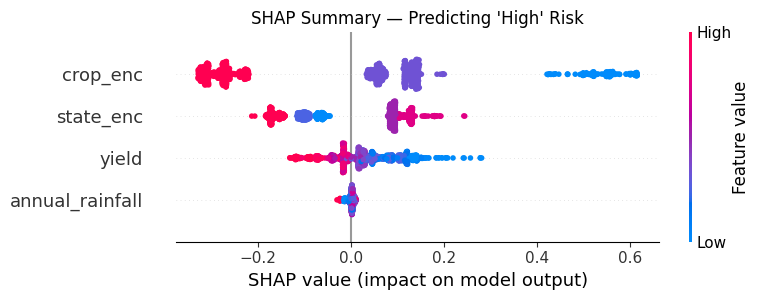

In [27]:
import numpy as np
import shap

# Recompute shap_values fresh so it matches the CURRENT X_test
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

print(type(shap_values))
print(np.array(shap_values).shape)
print(rf_model.classes_)
print(data['risk'].value_counts())

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values[:, :, 0], X_test, show=False)  # index 0 = 'High' class
plt.title("SHAP Summary — Predicting 'High' Risk")
plt.tight_layout()
plt.show()

## Advanced Exploration: Embedding and Clustering of Risk Patterns

Instead of using complex transformer-based embeddings (unnecessary for 
this dataset size), a simple numerical embedding is created for each 
state-crop combination using yield, CV, and rainfall. These embeddings 
are then clustered to group state-crop combinations with similar risk 
behavior.

In [28]:
counts = data.groupby(['state', 'crop']).size().reset_index(name='n_obs')
counts.sort_values('n_obs')

,state,crop,n_obs
13,madhya pradesh,Ragi,8
3,andhra pradesh,Ragi,129
18,maharashtra,Ragi,141
0,andhra pradesh,Cotton(lint),154
24,tamil nadu,Rice,155
1,andhra pradesh,Groundnut,155
4,andhra pradesh,Rice,156
2,andhra pradesh,Maize,156
10,madhya pradesh,Cotton(lint),230
8,karnataka,Ragi,268


In [29]:
# Get observation counts per state-crop pair
counts = data.groupby(['state', 'crop']).size().reset_index(name='n_obs')

# Keep only reasonably-sized groups (threshold: at least 50 observations)
reliable_groups = counts[counts['n_obs'] >= 50][['state', 'crop']]

# Filter main data to only these reliable groups
data_reliable = data.merge(reliable_groups, on=['state', 'crop'], how='inner')

print("Rows before filtering:", len(data))
print("Rows after filtering:", len(data_reliable))
print("State-crop pairs remaining:", data_reliable.groupby(['state','crop']).ngroups)

Rows before filtering: 6802
Rows after filtering: 6794
State-crop pairs remaining: 24


In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

embed_df = data_reliable.groupby(['state', 'crop']).agg(
    mean_yield=('yield', 'mean'),
    cv=('cv', 'mean'),
    mean_rainfall=('annual_rainfall', 'mean')
).reset_index()

scaler = StandardScaler()
X_embed = scaler.fit_transform(embed_df[['mean_yield', 'cv', 'mean_rainfall']])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
embed_df['cluster'] = kmeans.fit_predict(X_embed)

embed_df.sort_values('cluster')

,state,crop,mean_yield,cv,mean_rainfall,cluster
0,andhra pradesh,Cotton(lint),2.337013,46.322326,1022.937013,0
1,andhra pradesh,Groundnut,1.895484,56.691692,1020.969032,0
2,andhra pradesh,Maize,4.022179,32.682151,1023.689103,0
3,andhra pradesh,Ragi,1.176512,35.207888,1039.817829,0
4,andhra pradesh,Rice,3.161795,21.159896,1023.689103,0
5,karnataka,Cotton(lint),2.437701,45.558974,1018.242336,0
6,karnataka,Groundnut,0.886019,41.373800,1163.930408,0
7,karnataka,Maize,3.237304,34.257308,1163.864890,0
8,karnataka,Ragi,1.485261,33.203554,1116.261940,0
9,karnataka,Rice,2.738364,28.025548,1259.746667,0


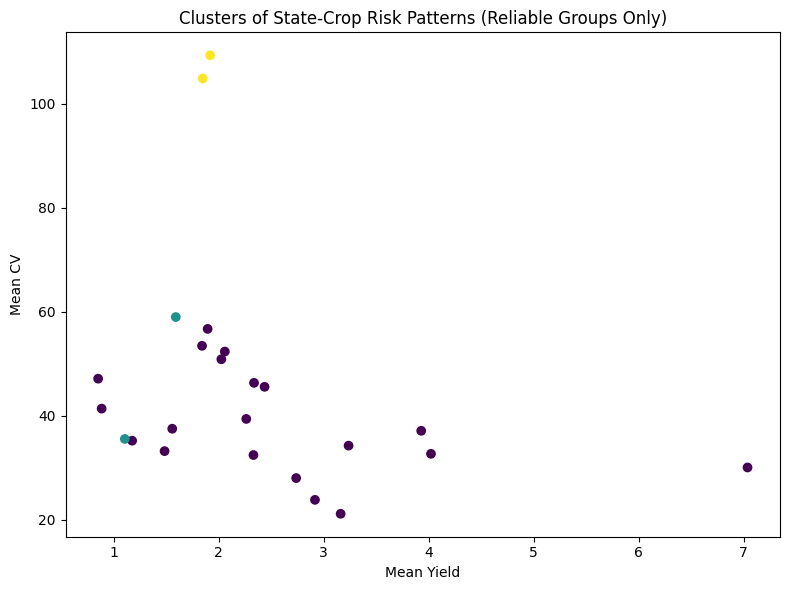

In [31]:
plt.figure(figsize=(8, 6))
plt.scatter(embed_df['mean_yield'], embed_df['cv'], c=embed_df['cluster'], cmap='viridis')
plt.xlabel("Mean Yield")
plt.ylabel("Mean CV")
plt.title("Clusters of State-Crop Risk Patterns (Reliable Groups Only)")
plt.tight_layout()
plt.show()

Interpretation of Clusters

Clustering the 24 reliable state-crop combinations produced 3 groups:

Cluster 0 (20 combinations): Most state-crop pairs, with moderate CV (21–57) and moderate rainfall — the typical case.
Cluster 1 (Maharashtra Rice, Maharashtra Ragi): Very high rainfall (1600–2200mm), but normal CV — showing that even extreme rainfall doesn't push risk up.
Cluster 2 (Maharashtra Cotton, Madhya Pradesh Cotton): By far the highest CV (104–109) — both are Cotton, matching the earlier finding that Cotton is one of the riskiest crops.

## Decision Support: From Risk Analysis to Real-World Action

This analysis shows that agricultural risk is driven primarily by 
**crop type (53% feature importance)** and **state (27%)**, while 
rainfall contributes very little (1.5%) — confirmed independently by 
correlation analysis (r = 0.038), Random Forest feature importance, 
and clustering (Cotton stood out as high-risk regardless of rainfall).

**For Farmers:**
- Crop choice matters more than hoping for good rainfall. Farmers in 
  high-risk regions (e.g. Maharashtra, Madhya Pradesh) growing Cotton 
  should be aware it is consistently the highest-risk crop in this 
  dataset (CV of 104–109, nearly double any other crop).
- Farmers seeking stability over maximum yield can refer to the 
  stability-adjusted ranking (Week 4–5) to pick crops that balance 
  yield with lower year-to-year variability.

**For Government / Policy:**
- Since rainfall is not the main driver of risk, irrigation investment 
  alone will not solve instability — crop-specific and state-specific 
  support (e.g. better seed varieties, storage, insurance) will likely 
  have more impact.
- Crop insurance premiums or subsidies could be differentiated by 
  crop-state combination using this risk ranking, rather than a flat 
  rate — directing more support toward genuinely high-risk combinations 
  like Cotton in Maharashtra and Madhya Pradesh.
- The clustering output offers a simple way to group regions for 
  planning: "stable" (Cluster 0), "high rainfall but stable" (Cluster 1), 
  and "high-risk crop, needs support" (Cluster 2).

**Overall:** This analysis moves beyond simply reporting average yield, 
offering a risk-aware view that can guide both individual crop choices 
and broader agricultural policy.